find out using exploratory data analysis: 
- How much data is missing, and whether certain stations are more affected
- How water levels vary between stations and over time
- Which characteristics of the stations would be useful for clustering.
- Whether missing data could bias your clustering and flood prediction models.

Station locations - Plot all stations on a map to see their geographical distribution
Missing data per station - Identify which stations have the most missing readings
Water-level distributions - Use histograms or boxplots to compare stations
Water levels over time - Plot a few stations to investigate trends and seasonal patterns



Minimum vs average vs maximum levels

MLP week on clustering: week 3
Once we have chosen or designed a measure of dissimilarity between observations in our
dataset, our objective is to try and assign each data point to one of K distinct clusters
(with K < N )
Our goal is to find the clustering C which minimises the total within cluster variation,
that is, we seek a method to partition the observations into K groups such that the loss
in (3) is minimised
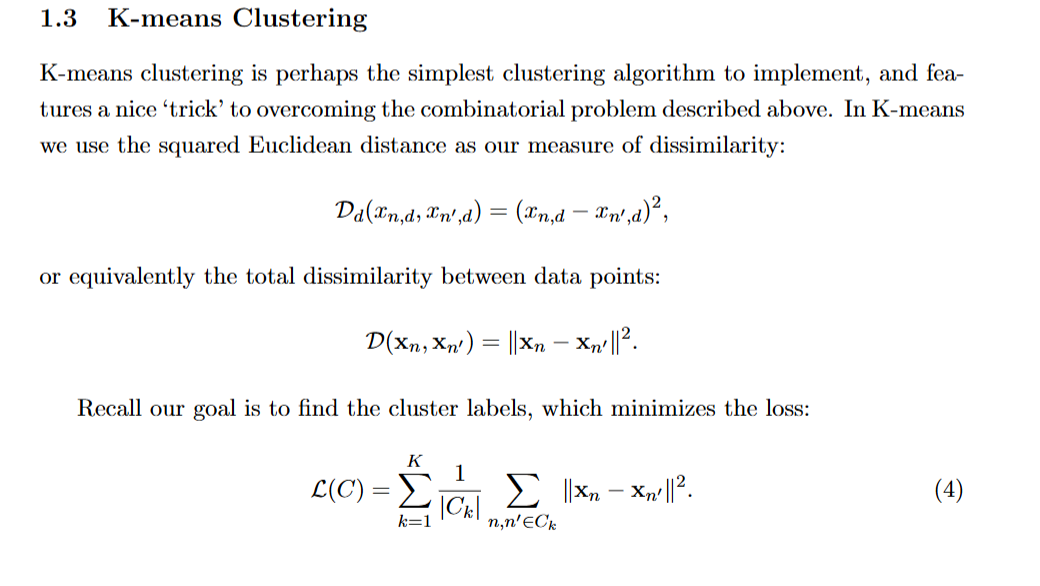
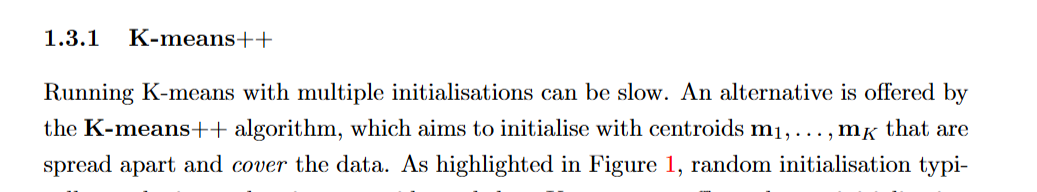
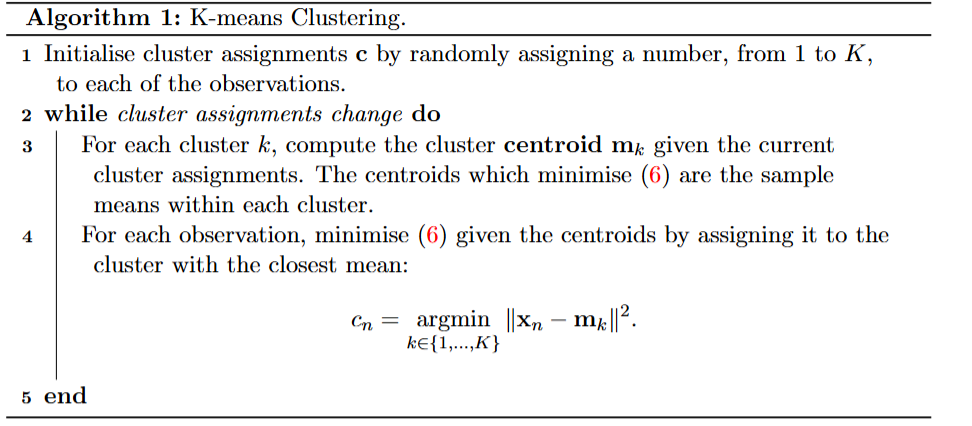

In [2]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")
df_avg.head()

#checking the locations of missing data is the same for min max avg
min_missing = df_min.iloc[:, 3:].isna()
max_missing = df_max.iloc[:, 3:].isna()
avg_missing = df_avg.iloc[:, 3:].isna()

print(min_missing.equals(max_missing))
print(min_missing.equals(avg_missing))
print(max_missing.equals(avg_missing))


True
True
True


In [7]:
#Water level data only
avg = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")
min_level = df_min.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")
max_level = df_max.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

#Create new dataset
df_features = df_avg[["County", "Station_Name", "Observation_ID"]].copy()

#Average water level behaviour 
avg = df_avg.iloc[:, 3:]
min_level = df_min.iloc[:, 3:]
max_level = df_max.iloc[:, 3:]

#seeing how many have been replaced with invalid numbers 
print((min_level.abs() >= 999999).sum().sum())
print((max_level.abs() >= 999999).sum().sum())
print((avg.abs() >= 999999).sum().sum())

#replacing the invalid ones with nan
avg = avg.replace(999999.999, np.nan)
min_level = min_level.replace(-999999.999, np.nan)
max_level = max_level.replace(999999.999, np.nan)

#Calculating the daily range and the change between days 
daily_range = max_level - min_level
daily_change = avg.copy().diff(axis=1)


#Calculating all of the features
df_features["Std_Level"] = avg.std(axis=1)
df_features["Mean_Daily_Range"] = daily_range.mean(axis=1)
df_features["Std_Daily_Range"] = daily_range.std(axis=1)
df_features["Max_Daily_Range"] = daily_range.max(axis=1)
df_features["Std_Daily_Change"] = daily_change.std(axis=1)
df_features["95th_Daily_Range"] = daily_range.quantile(0.95, axis=1)
df_features["Missing_Percent"] = avg.isna().mean(axis=1) * 100
df_features["90th_Daily_Range"] = daily_range.quantile(0.90, axis=1)

#percent of days in each station that have a range above the 90th percentile of ranges
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.gt.html used this 
threshold = daily_range.stack().quantile(0.90)
df_features["Percent_Above_90th"] = (
    daily_range.gt(threshold).sum(axis=1)
    / daily_range.notna().sum(axis=1) * 100
)

#how far a stations water levels deviate from its own average 
#https://www.statisticshowto.com/average-deviation/ used this 
df_features["Mean_Absolute_Deviation"] = (
    avg.sub(avg.mean(axis=1), axis=0).abs().mean(axis=1)
)

df_features.to_csv("df_features.csv", index=False)



30
47
1


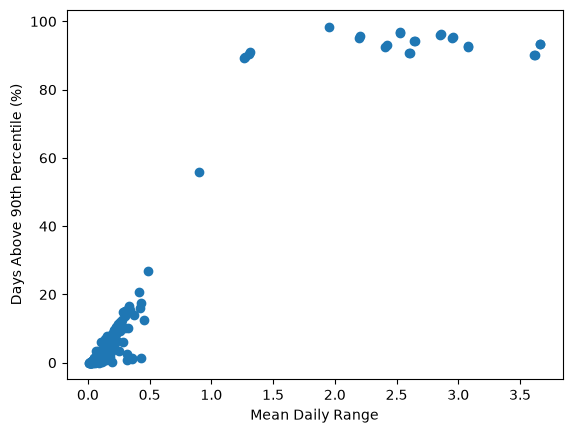

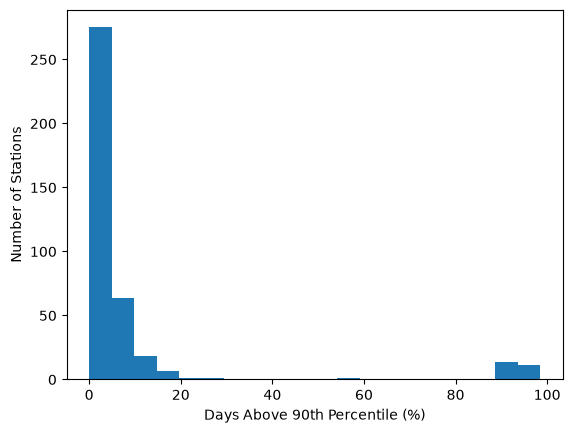

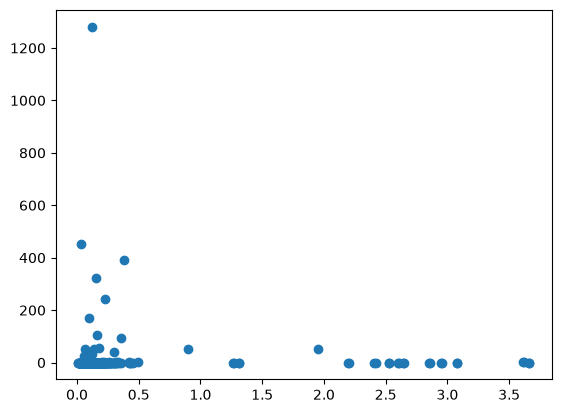

In [11]:
plt.scatter(df_features["Mean_Daily_Range"],
            df_features["Percent_Above_90th"])

plt.xlabel("Mean Daily Range")
plt.ylabel("Days Above 90th Percentile (%)")
plt.show()

Q1 = df_features["90th_Daily_Range"].quantile(0.25)
Q3 = df_features["90th_Daily_Range"].quantile(0.75)

IQR = Q3 - Q1


plt.hist(df_features["Percent_Above_90th"], bins=20)
plt.xlabel("Days Above 90th Percentile (%)")
plt.ylabel("Number of Stations")
plt.show()

plt.scatter(df_features["Mean_Daily_Range"],
            df_features["Mean_Absolute_Deviation"])

plt.show()

the min has been replaced by -999999.999 30 times
the max has been repalced by 999999.999 47 times 
the avg has been replaced by 999999.999 1 time 

Cluster
0.0    369
1.0     21
2.0      2
Name: count, dtype: int64


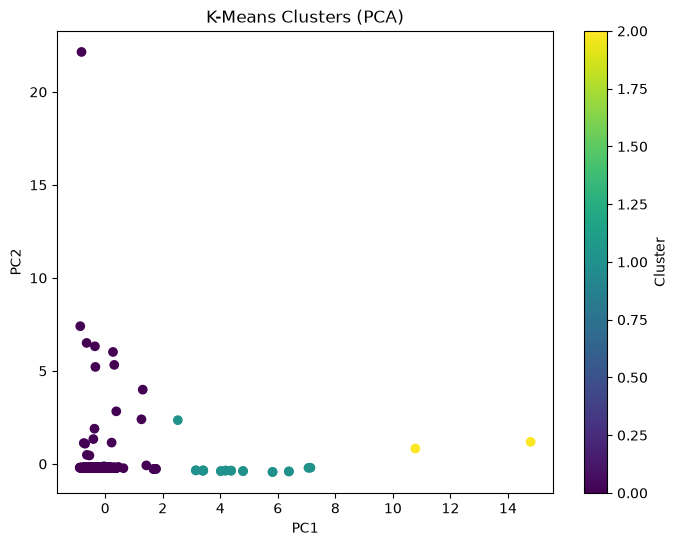

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Select features
X = df_features[["Std_Level", "Mean_Daily_Range", "Std_Daily_Range", "Max_Daily_Range", "Std_Daily_Change", "95th_Daily_Range"]].dropna()

# Standardise features
X_scaled = StandardScaler().fit_transform(X)

# K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df_features.loc[X.index, "Cluster"] = kmeans.fit_predict(X_scaled)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X = df_features[["Std_Level", "Mean_Daily_Range", "Std_Daily_Range", "Max_Daily_Range", "Std_Daily_Change", "95th_Daily_Range"]].dropna()

X_scaled = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42)

df_features["Cluster"] = np.nan
df_features.loc[X.index, "Cluster"] = kmeans.fit_predict(X_scaled)

print(df_features["Cluster"].value_counts())


# Plot clusters
plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=df_features.loc[X.index, "Cluster"],
            cmap="viridis")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters (PCA)")
plt.colorbar(label="Cluster")
plt.show()
df_map = df_locs.merge(df_features, on="Observation_ID")

df_map.to_csv("station_clusters.csv", index=False)

avg is missing 525,877 values (30.61%)
min is missing 525,877 values (30.61%)
max is missing 525,877 values (30.61%)


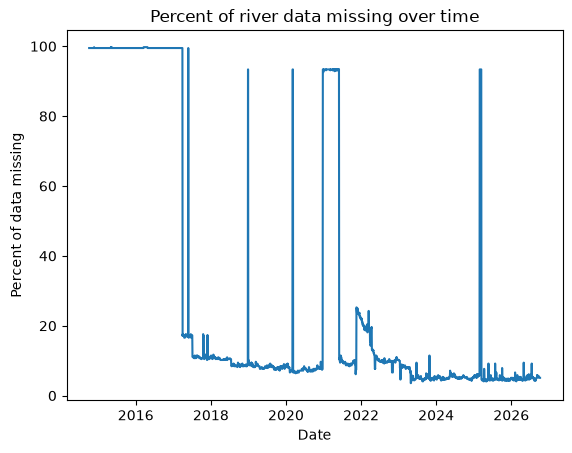

In [43]:
#missing value investigations

for name, df in [("avg", df_avg), ("min", df_min), ("max", df_max)]:
    missing = df.isna().sum().sum()
    total = df.size
    print(f"{name} is missing {missing:,} values ({missing / total * 100:.2f}%)")


#plotting the missing values againt date
missing = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100

plt.plot(pd.to_datetime(missing.index, dayfirst=True), missing)
plt.xlabel("Date")
plt.ylabel("Percent of data missing")
plt.title("Percent of river data missing over time")
plt.show()





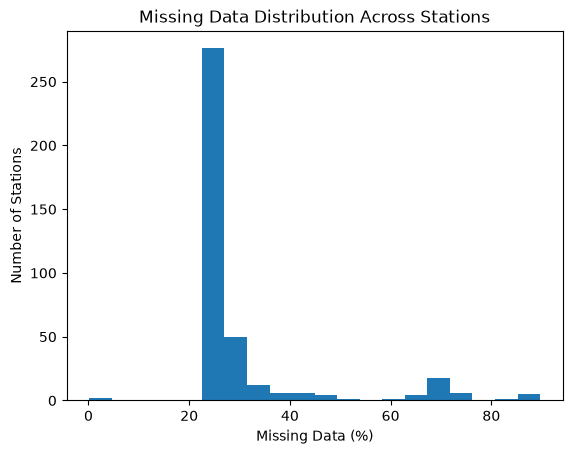

In [44]:
#histograms of the missing values 
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

plt.hist(missing_station, bins=20)
plt.xlabel("Missing Data (%)")
plt.ylabel("Number of Stations")
plt.title("Missing Data Distribution Across Stations")
plt.show()

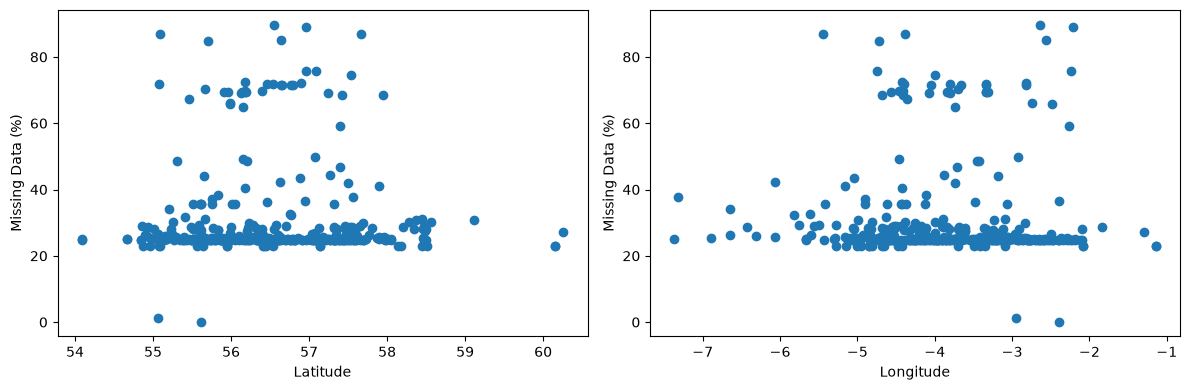

In [45]:
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].scatter(df_locs["Latitude"], missing_station)
axs[0].set_xlabel("Latitude")
axs[0].set_ylabel("Missing Data (%)")

axs[1].scatter(df_locs["Longitude"], missing_station)
axs[1].set_xlabel("Longitude")
axs[1].set_ylabel("Missing Data (%)")

plt.tight_layout()
plt.show()

#the above does not show as well where the missing data is concentrated 


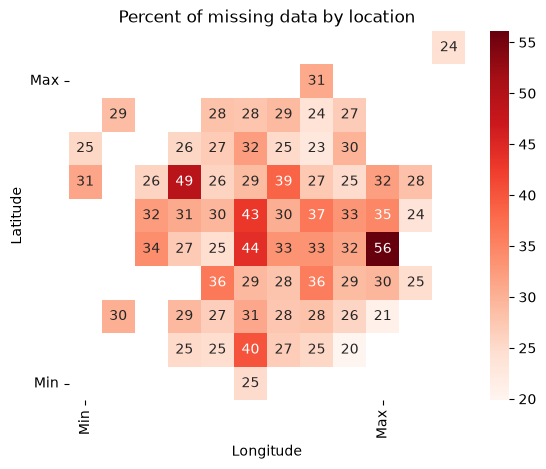

In [ ]:
#https://seaborn.pydata.org/generated/seaborn.heatmap.html as a reference and the week 1 workshop
#https://pandas.pydata.org/docs/reference/api/pandas.cut.html

#colour map
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

df_map = df_locs.copy()
df_map["Missing"] = missing_station

#sorting into categorical variables
df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12, ordered = True)
df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

heatmap_data = df_map.pivot_table(values="Missing",index="Latitude",columns="Longitude")
sns.heatmap(heatmap_data, annot=True, cmap = 'Reds')
plt.title("Percent of missing data by location")
plt.xticks([0.5, 9.5], ["Min", "Max"])
plt.yticks([0.5, 9.5], ["Min", "Max"])
plt.gca().invert_yaxis()
plt.show()

#adding a column of the missing stations 

df_map = df_locs.merge(df_avg[["Observation_ID"]].assign(Missing_Percent=missing_station),on="Observation_ID")
df_map.to_csv("scotland_missing_data.csv", index=False)
df_map["Missing_Percent"] = pd.to_numeric(df_map["Missing_Percent"])
df_map.to_csv("scotland_missing_data.csv", index=False)



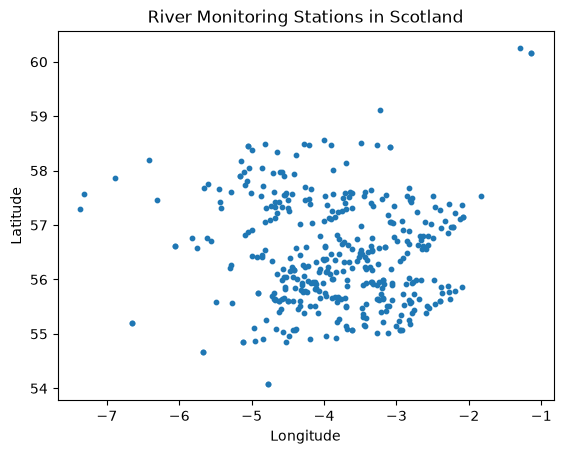

In [22]:
#map of the stations for clustering 

plt.scatter(df_locs["Longitude"], df_locs["Latitude"], s=10)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("River Monitoring Stations in Scotland")
plt.show()

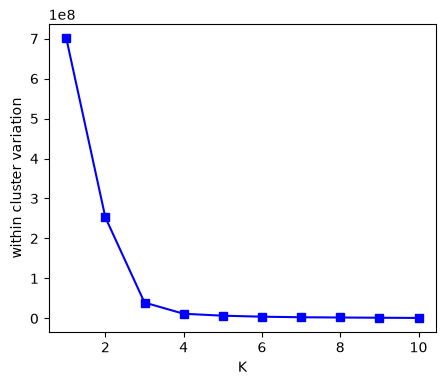

In [ ]:

# Select features
X = df_features.drop(columns=["County", "Station_Name", "Observation_ID"]).dropna()

#kmeans clustering from clustering workshop exercise 5, within cluster variation

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import seaborn as sns 

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster import hierarchy

K = np.arange(1,11)
WCV = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters = K[i], n_init = 20, random_state=0).fit(X)
    WCV[i] = kmeans_K.inertia_

fig, ax = plt.subplots(1,1,figsize=(5,4))
ax.plot(K, WCV, c='b',marker='s')
plt.xlabel('K')
plt.ylabel('within cluster variation')
plt.show()

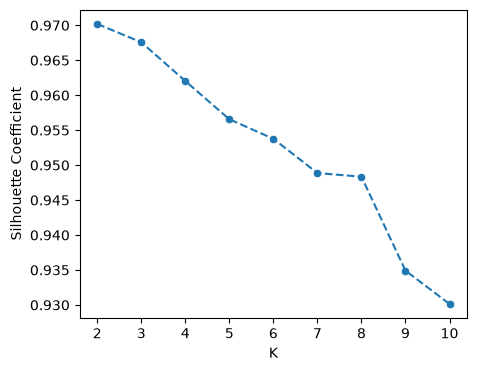

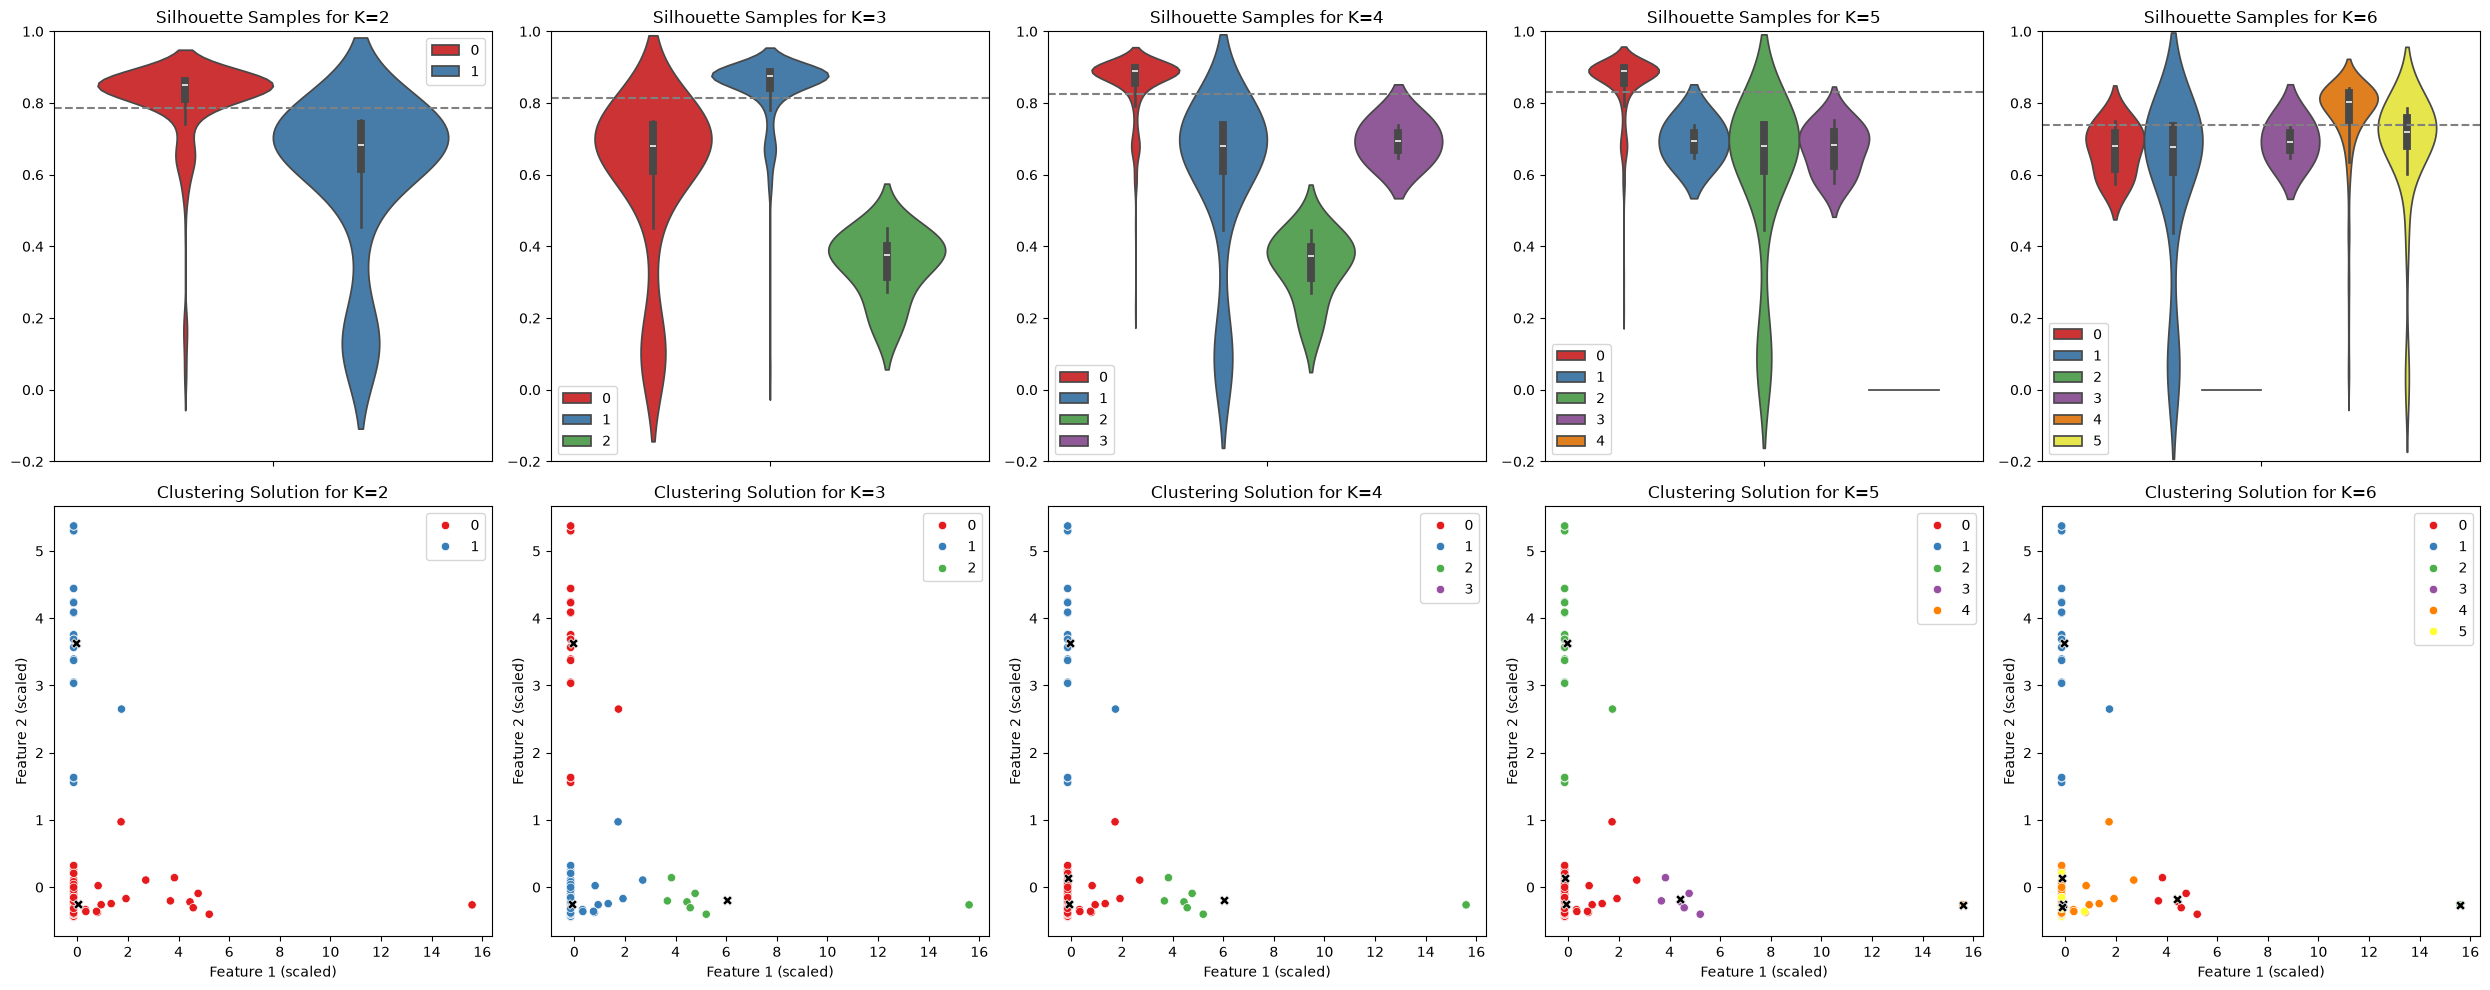

In [40]:
#silhouette analysis, clustering workshop question 6 
from sklearn.metrics import silhouette_samples, silhouette_score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples
from sklearn.preprocessing import StandardScaler


# Define the range of possible number of clusters
K = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])

# First plot the silhouette coeffcient for different choices of K
silhouette_coeffs = np.zeros(K.shape)
for i in range(K.shape[0]):
    #Define kmeans object, fit, and predict labels
    kmeans_K = KMeans(n_clusters = K[i], n_init = 20, random_state=0).fit(X)
    labs = kmeans_K.predict(X)
    # Compute silhouette coefficient
    silhouette_coeffs[i] = silhouette_score(X, labs)

# Plot the silhouette coefficients
fig, ax = plt.subplots(1,1,figsize=(5,4))
sns.lineplot(x=K, y=silhouette_coeffs, linestyle='dashed', ax=ax)
sns.scatterplot(x=K, y=silhouette_coeffs, ax=ax)
plt.xlabel('K')
plt.ylabel('Silhouette Coefficient')
plt.show()

# Scale features
X_scaled = StandardScaler().fit_transform(X)

K = [2, 3, 4, 5, 6]

fig, ax = plt.subplots(2, 5, figsize=(25, 10))

for i in range(len(K)):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(X_scaled)
    labs = kmeans_K.labels_
    silhouette_samps = silhouette_samples(X_scaled, labs)

    # Violin plot
    sns.violinplot(y=silhouette_samps, hue=labs, ax=ax[0, i], palette='Set1')
    ax[0, i].axhline(silhouette_samps.mean(), ls='--', c="gray")
    ax[0, i].set_title(f'Silhouette Samples for K={K[i]}')
    ax[0, i].set_ylim([-0.2, 1])

    # Clustering solution
    sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1],
                    hue=labs, ax=ax[1, i], palette='Set1')

    sns.scatterplot(x=kmeans_K.cluster_centers_[:, 0],
                    y=kmeans_K.cluster_centers_[:, 1],
                    color='black', s=50, marker='X', ax=ax[1, i])

    ax[1, i].set_title(f'Clustering Solution for K={K[i]}')
    ax[1, i].set_xlabel('Feature 1 (scaled)')
    ax[1, i].set_ylabel('Feature 2 (scaled)')

plt.tight_layout()
plt.show()

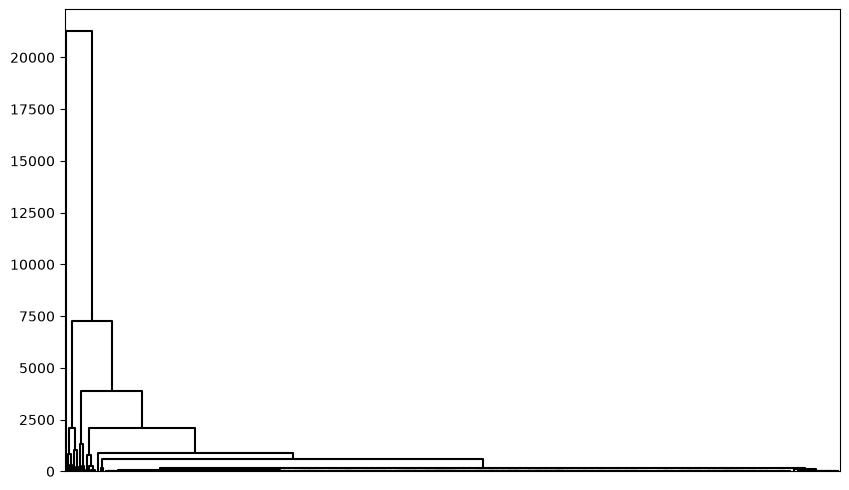

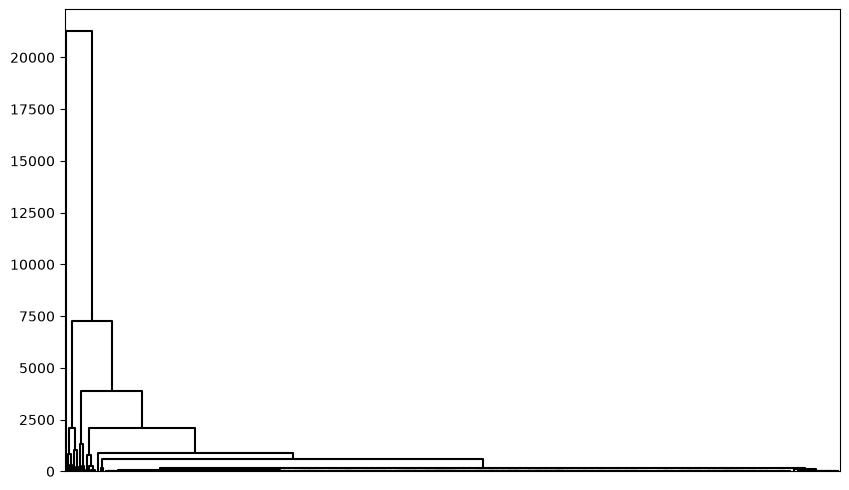

InvalidIndexError: (slice(None, None, None), 0)

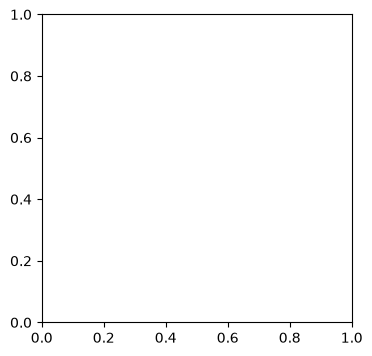

In [46]:
#heirarchial clustering - clustreing workshop exericse 8
hc_comp = hierarchy.linkage(X, method='complete')

# Plot the dendrogram
fig, ax = plt.subplots(1, 1, figsize=(10,6))
hierarchy.dendrogram(hc_comp, ax=ax, no_labels=True,
                     color_threshold=-np.inf, above_threshold_color='black')
plt.show()

# Change the color threshold to visualize clusters obtained by cutting the tree
fig, ax = plt.subplots(1, 1, figsize=(10,6))
hierarchy.dendrogram(hc_comp, ax=ax, no_labels=True,
                     color_threshold=0, above_threshold_color='black')
plt.show()

# Cut the tree at a specified number of clusters
hc_cl = hierarchy.cut_tree(hc_comp, n_clusters=3)

fig, ax = plt.subplots(1,1,figsize=(4,4))
sns.scatterplot(x=X[:,0], y=X[:,1], hue=hc_cl.reshape(-1), palette='Set1', s=10, ax=ax)
ax.set_title('Hierarchical Clustering with complete linkage, specified no of clusters')
plt.show()

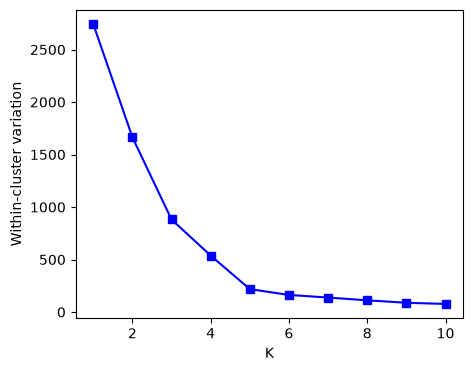

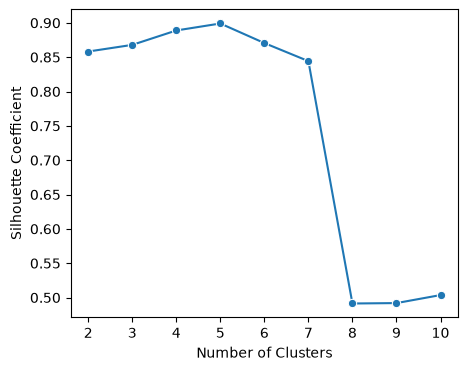

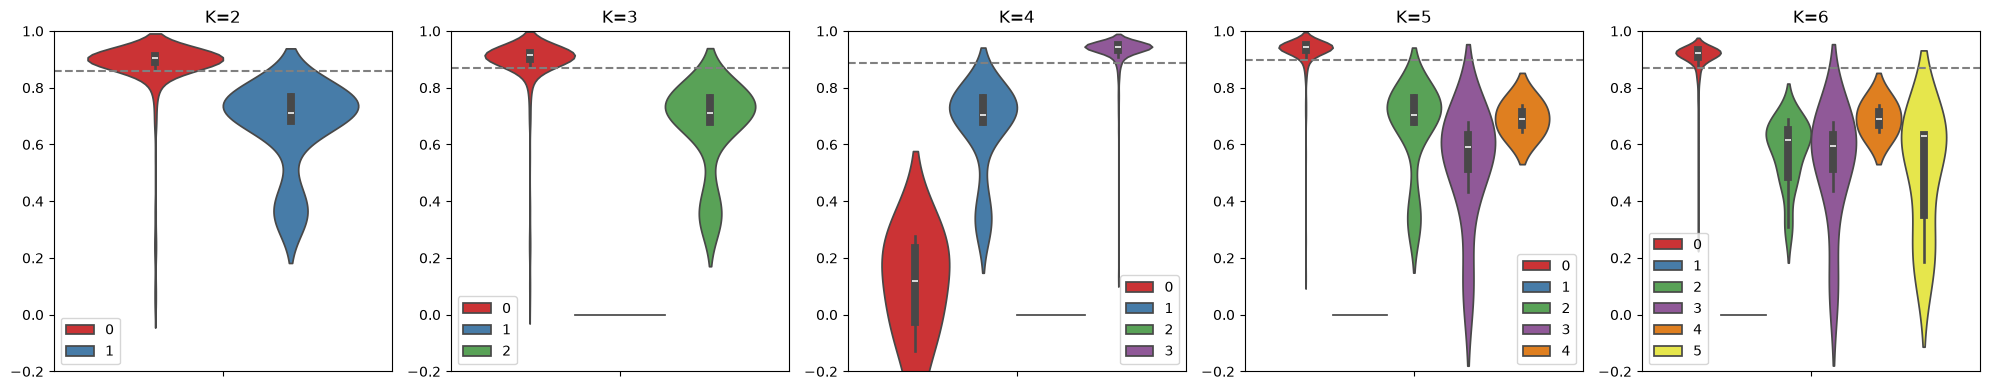

Cluster
0.0    357
2.0     25
3.0      7
4.0      2
1.0      1
Name: count, dtype: int64


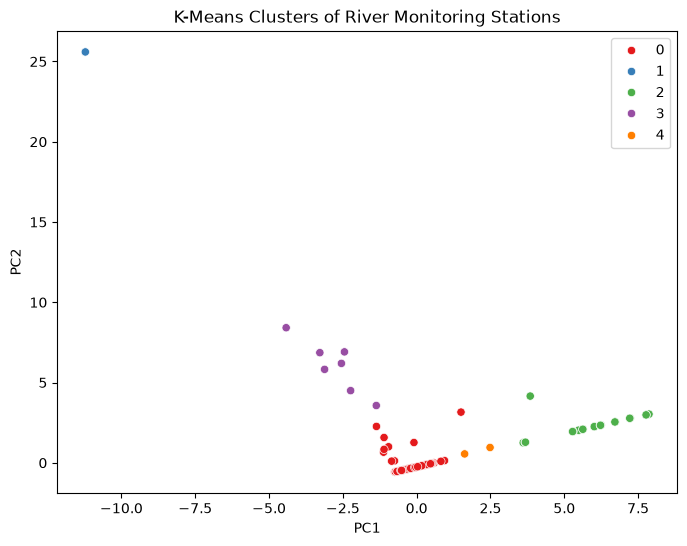

In [56]:
#CLUSTERING WEEK 3 WORKSHOP ADAPTATION

#ex 7 adaptation, preparing the data 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

# Choose river behaviour features - NOTE discuss with emma and gabi what features they want to put bc idk
features = [
    "Std_Level",
    "Mean_Daily_Range",
    "Std_Daily_Range",
    "Std_Daily_Change",
    "Mean_Absolute_Deviation",
    "90th_Daily_Range",
    "Percent_Above_90th"
]

X = df_features[features].dropna()

# Standardise data 
ss = StandardScaler()
Xs = ss.fit_transform(X)

#workshop 5 adaptation, elbow plot
# Workshop Exercise 5: Within-cluster variation

K = np.arange(1, 11)
WCV = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    WCV[i] = kmeans_K.inertia_

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(K, WCV, c='b', marker='s')
plt.xlabel('K')
plt.ylabel('Within-cluster variation')
plt.show()

#ex 6 - silhouette analysis
# Workshop Exercise 6: Silhouette scores

K = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])
silhouette_coeffs = np.zeros(K.shape)

for i in range(K.shape[0]):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    labs = kmeans_K.predict(Xs)

    silhouette_coeffs[i] = silhouette_score(Xs, labs)

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
sns.lineplot(x=K, y=silhouette_coeffs, marker='o', ax=ax)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Coefficient')
plt.show()

#ex 6 - violin plots 
# Workshop Exercise 6: Silhouette sample distributions

fig, ax = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    kmeans_K = KMeans(n_clusters=K[i], n_init=20, random_state=0).fit(Xs)
    labs = kmeans_K.labels_
    silhouette_samps = silhouette_samples(Xs, labs)

    sns.violinplot(y=silhouette_samps, hue=labs,
                   ax=ax[i], palette='Set1')

    ax[i].axhline(silhouette_samps.mean(), ls='--', c='gray')
    ax[i].set_title(f'K={K[i]}')
    ax[i].set_ylim([-0.2, 1])

plt.tight_layout()
plt.show()

#k means clustering by ex 12 

kmeans = KMeans(n_clusters=5, n_init=20, random_state=0).fit(Xs)

df_features["Cluster"] = np.nan
df_features.loc[X.index, "Cluster"] = kmeans.labels_

print(df_features["Cluster"].value_counts())

#PCA analysis - adapted from ex 10 and 13
# Workshop Exercises 10 and 13: PCA visualisation

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
scores = pca.fit_transform(Xs)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

sns.scatterplot(
    x=scores[:, 0],
    y=scores[:, 1],
    hue=kmeans.labels_,
    palette='Set1',
    ax=ax
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('K-Means Clusters of River Monitoring Stations')

plt.show()

#table of the stats for each of the clusters
df_features.groupby("Cluster")[features].median()

df_map = df_locs.merge(
    df_features[["Observation_ID", "Cluster"]],
    on="Observation_ID"
)

df_map.to_csv("station_clusters.csv", index=False)